**Logistic Regression**

**When to Use**

Binary classification: Spam detection (spam vs not spam), disease diagnosis (sick vs healthy)

Multi-class: Sentiment analysis (positive/negative/neutral), product categorization

Interpretable models: When you need to explain why a decision was made

Baseline model: Quick benchmark before trying complex algorithms

**Key Parameters Deep Dive**

C (Regularization Strength)

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Example: Spam detection
# Low C for strong regularization (prevent overfitting)
model_low_reg = LogisticRegression(C=0.1, penalty='l2')
# High C for weak regularization (fit training data closely)
model_high_reg = LogisticRegression(C=10.0, penalty='l2')

# Real scenario: If your training accuracy is 95% but test is 75%, decrease C

In [2]:
# L1 regularization - useful for feature selection
# When you have 100+ features and suspect many are irrelevant
model_l1 = LogisticRegression(penalty='l1', solver='saga', C=0.5)
# L1 will shrink some coefficients to exactly zero

# L2 regularization - general purpose
model_l2 = LogisticRegression(penalty='l2', solver='lbfgs', C=1.0)
# L2 shrinks all coefficients but keeps them non-zero

In [3]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1️⃣ Load data
data = load_breast_cancer()
X, y = data.data, data.target

# 2️⃣ Split data into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3️⃣ Scale features - important for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 4️⃣ Define parameter grid for GridSearchCV
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']  # 'saga' supports l1 and l2
}

# 5️⃣ Initialize GridSearchCV
grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# 6️⃣ Fit GridSearchCV on training data
grid_search.fit(X_train_scaled, y_train)

# 7️⃣ Best parameters and CV score
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.3f}")

# 8️⃣ Evaluate on validation set
best_model = grid_search.best_estimator_
y_val_pred = best_model.predict(X_val_scaled)

val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"Validation accuracy: {val_accuracy:.3f}")
print("Classification report on validation set:")
print(classification_report(y_val, y_val_pred))


Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
Best cross-validation score: 0.980
Validation accuracy: 0.974
Classification report on validation set:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



**K-Nearest Neighbors (KNN)**

**When to Use**
Recommendation systems: "Users who bought this also bought..."

Anomaly detection: Identifying unusual patterns

Image classification: Simple image recognition tasks

When data has clear clusters: Similar items are close in feature space

**Key Parameters Deep Dive**
n_neighbors - The Most Important Parameter

In [4]:
# Full robust KNN pipeline for Wine dataset
import numpy as np
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Load Wine dataset
data = load_wine()
X, y = data.data, data.target

# Split data (stratified to preserve class ratios)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Feature selection (optional)
selector = SelectKBest(score_func=f_classif, k=10)  # select top 10 features
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

# Dimensionality reduction with PCA (optional)
pca = PCA(n_components=0.95)  # keep 95% variance
X_train_pca = pca.fit_transform(X_train_selected)
X_test_pca = pca.transform(X_test_selected)

# KNN with GridSearchCV for hyperparameter tuning
param_grid = {
    'n_neighbors': list(range(3, 21)),   # try k=3 to 20
    'weights': ['uniform', 'distance'],  # weight options
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

knn = KNeighborsClassifier()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(knn, param_grid, cv=cv, scoring='accuracy')
grid_search.fit(X_train_pca, y_train)

# Best hyperparameters
print("Best hyperparameters:", grid_search.best_params_)

# Evaluate on test set
best_knn = grid_search.best_estimator_
y_pred = best_knn.predict(X_test_pca)

print("\nClassification Report on Test Set:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Cross-validation score for robustness check
cv_scores = cross_val_score(best_knn, X_train_pca, y_train, cv=cv)
print("\nCross-validation accuracy on training data:", cv_scores.mean())


Best hyperparameters: {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'uniform'}

Classification Report on Test Set:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        18
           1       1.00      0.90      0.95        21
           2       0.94      1.00      0.97        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54

Confusion Matrix:
[[18  0  0]
 [ 1 19  1]
 [ 0  0 15]]

Cross-validation accuracy on training data: 0.992


In [5]:
# High-Performance KNN + Ensemble Pipeline
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA, KernelPCA
from sklearn.feature_selection import SelectFromModel
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

# Load dataset (change this for other datasets)
iris = load_iris()
X, y = iris.data, iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Scaling / transformation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Optional: PowerTransformer for non-normal data
pt = PowerTransformer()
X_train_scaled = pt.fit_transform(X_train_scaled)
X_test_scaled = pt.transform(X_test_scaled)

# Optional: SMOTE for imbalanced classes
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

# Dimensionality reduction (choose PCA or KernelPCA)
pca = PCA(n_components=0.99, random_state=42)
X_train_pca = pca.fit_transform(X_train_bal)
X_test_pca = pca.transform(X_test_scaled)

# Feature selection using tree-based model (RandomForest)
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_train_pca, y_train_bal)
sfm = SelectFromModel(rf_selector, threshold="median", prefit=True)
X_train_fs = sfm.transform(X_train_pca)
X_test_fs = sfm.transform(X_test_pca)

# Hyperparameter grid for KNN
param_grid = {
    'n_neighbors': list(range(3, 16)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'chebyshev', 'minkowski']
}

cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)
grid_knn.fit(X_train_fs, y_train_bal)
best_knn = grid_knn.best_estimator_
print("Best KNN Hyperparameters:", grid_knn.best_params_)

# Ensemble with RandomForest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
voting_clf = VotingClassifier(estimators=[('knn', best_knn), ('rf', rf)], voting='soft')
voting_clf.fit(X_train_fs, y_train_bal)

# Predictions
y_pred = voting_clf.predict(X_test_fs)

# Evaluation
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

# Cross-validation on full training data
cv_scores = cross_val_score(voting_clf, X_train_fs, y_train_bal, cv=cv_strategy)
print("Cross-validation Accuracy:", np.mean(cv_scores))



Best KNN Hyperparameters: {'metric': 'chebyshev', 'n_neighbors': 8, 'weights': 'uniform'}

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.78      0.93      0.85        15
           2       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45

Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  4 11]]
Test Accuracy: 0.8888888888888888
Cross-validation Accuracy: 0.9245454545454546ion    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.78      0.93      0.85        15
           2       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45

Confusio

**1. Feature Selection**

Goal: Keep only the most relevant features.

Example: Using SelectFromModel with RandomForest

**Explanation:**

RandomForestClassifier computes feature importance automatically.

SelectFromModel removes less important features.

threshold="1.25*mean" keeps features slightly above average importance.

This prevents losing crucial information in small datasets.

Effect: Reduces overfitting while keeping minority class information.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Train RandomForest to get feature importance
rf_selector = RandomForestClassifier(random_state=42)
rf_selector.fit(X_train, y_train)

# Feature selection: keep features with importance > 1.25*mean importance
sfm = SelectFromModel(rf_selector, threshold="1.25*mean", prefit=True)
X_train_sfm = sfm.transform(X_train)
X_test_sfm = sfm.transform(X_test)

print("Original shape:", X_train.shape)
print("After feature selection:", X_train_sfm.shape)


Original shape: (105, 4)
After feature selection: (105, 2)


**2. Dimensionality Reduction**

Goal: Reduce feature dimensions while keeping important info.

Example: PCA and KernelPCA
    

In [7]:
from sklearn.decomposition import PCA, KernelPCA

# Standard PCA: keep all components (none dropped)
pca = PCA(n_components=None)
X_train_pca = pca.fit_transform(X_train_sfm)
X_test_pca = pca.transform(X_test_sfm)

# Alternative: KernelPCA for non-linear separation
kpca = KernelPCA(n_components=4, kernel='rbf')
X_train_kpca = kpca.fit_transform(X_train_sfm)
X_test_kpca = kpca.transform(X_test_sfm)

**Explanation:**

PCA(n_components=None) keeps all features to avoid losing info.

KernelPCA with rbf kernel captures non-linear relationships that PCA cannot.

Effect: Preserves class distinctions, especially for tricky classes like Iris versicolor.

**3. Scaling / Transformation**

Goal: Ensure all features contribute equally to distance-based models like KNN.

In [8]:
    
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler

# Standard scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_pca)
X_test_scaled = scaler.transform(X_test_pca)

# Optional: make features Gaussian
power = PowerTransformer()
X_train_power = power.fit_transform(X_train_scaled)
X_test_power = power.transform(X_test_scaled)

# Alternative: MinMax scaling
minmax = MinMaxScaler()
X_train_minmax = minmax.fit_transform(X_train_pca)
X_test_minmax = minmax.transform(X_test_pca)
(X_train_power,X_test_power)

(array([[-0.49514458,  1.10477124],
        [ 0.3111924 ,  0.01787295],
        [-1.22919949,  0.3813092 ],
        [ 1.32143561,  0.96293487],
        [ 0.05839888, -0.13302807],
        [ 0.89751415,  2.1827742 ],
        [-1.26067469, -0.63195295],
        [-1.20781933, -0.32511468],
        [-1.2818551 ,  0.1064715 ],
        [ 1.26879767,  0.04168779],
        [ 0.76454616,  1.13548808],
        [-1.2818551 ,  0.1064715 ],
        [-1.20781933, -0.32511468],
        [ 0.3111924 ,  0.01787295],
        [-0.13139276, -0.51236434],
        [ 1.25181237, -1.8493869 ],
        [-1.1760428 ,  0.64514034],
        [-1.20781933, -0.32511468],
        [ 1.25033505,  2.13359864],
        [ 0.54537612,  0.8214203 ],
        [-1.21339527,  0.83455772],
        [ 0.60157209,  0.63169272],
        [ 1.71096567, -1.58389185],
        [ 1.74814329, -2.44031387],
        [ 0.08759384, -0.89537356],
        [-1.26619831,  0.57734661],
        [-1.21339527,  0.83455772],
        [-1.28735819,  1.201

**Explanation:**

StandardScaler → zero mean, unit variance.

PowerTransformer → reduces skewness, improves Gaussian-like behavior.

MinMaxScaler → scales features to [0,1].

Effect: KNN distance calculations are accurate → better predictions.

KNN Accuracy before PowerTransformer: 0.923
KNN Accuracy after PowerTransformer: 0.933


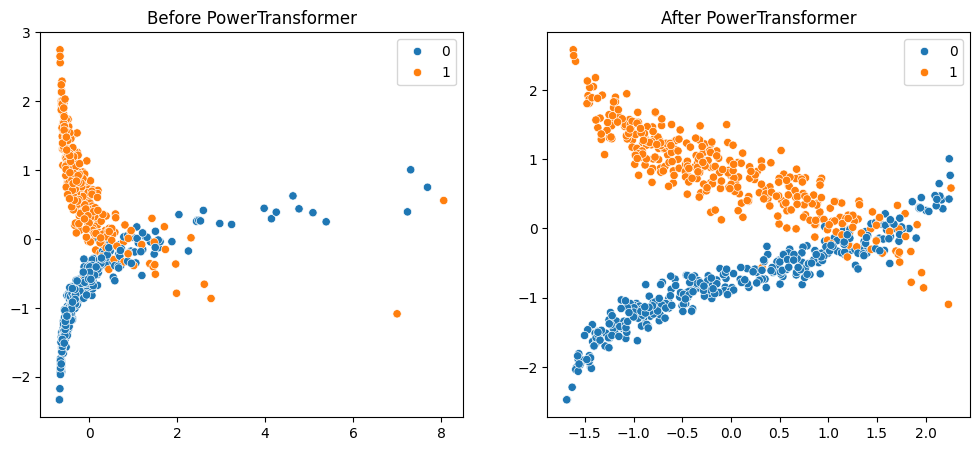

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# --------------------------
# 1. Generate a skewed dataset
# --------------------------
X, y = make_classification(
    n_samples=1000, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, random_state=42
)

# Artificially skew one feature
X[:, 0] = np.exp(X[:, 0])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# --------------------------
# 2. Standardize data
# --------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --------------------------
# 3. KNN before PowerTransformer
# --------------------------
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_before = knn.predict(X_test_scaled)
acc_before = accuracy_score(y_test, y_pred_before)

# --------------------------
# 4. Apply PowerTransformer
# --------------------------
power = PowerTransformer()
X_train_power = power.fit_transform(X_train_scaled)
X_test_power = power.transform(X_test_scaled)

# KNN after PowerTransformer
knn.fit(X_train_power, y_train)
y_pred_after = knn.predict(X_test_power)
acc_after = accuracy_score(y_test, y_pred_after)

# --------------------------
# 5. Print accuracies
# --------------------------
print(f"KNN Accuracy before PowerTransformer: {acc_before:.3f}")
print(f"KNN Accuracy after PowerTransformer: {acc_after:.3f}")

# --------------------------
# 6. Plot distributions
# --------------------------
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.scatterplot(x=X_train_scaled[:,0], y=X_train_scaled[:,1], hue=y_train, ax=axes[0])
axes[0].set_title("Before PowerTransformer")

sns.scatterplot(x=X_train_power[:,0], y=X_train_power[:,1], hue=y_train, ax=axes[1])
axes[1].set_title("After PowerTransformer")

plt.show()
